# Pharmacy Network and Channel Optimization

## Executive briefing

This notebook selects the set of pharmacies that should form a client network and decides where each
category of prescription is filled. It prices every design before any member feels it. For each candidate
network the business sees the savings against today, the number of members asked to change pharmacy, the
extra distance those members travel, and the access delivered to urban, rural, specialty and infusion
populations.

The engine solves classically in seconds and the identical model is the artifact submitted to D Wave. All
values in this run are synthetic. Column names follow the Optum claims warehouse so the real extract drops
in with no code change.

**How to read this notebook.** Sections 1 to 7 build the problem: settings, data, claims aggregation and
rules. Section 8 solves the default design. Section 9 runs nine client scenarios. Section 10 shows the
member impact of each scenario in business terms. Section 11 writes reference exports. Section 12 holds the
interactive charts intended for business review.

**The decision this supports.** Leadership picks one scenario from the menu. Every scenario shown is fully
lawful under the access, capacity, chain, mandate, quality and guarantee rules. The choice is a philosophy,
not a compliance question.

## 0. Packages and solver

```
pip install pyomo highspy pandas numpy matplotlib
```
HiGHS via Pyomo, exact MIP. Same model object ports to SCIP, Gurobi, or the D-Wave hybrid CQM solver.

In [1]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from math import radians, sin, cos, sqrt, atan2
from pyomo.environ import (ConcreteModel, Var, Objective, Constraint, ConstraintList,
                           Binary, NonNegativeReals, minimize, value, SolverFactory)
pd.set_option('display.width',170); pd.set_option('display.max_columns',30)
print('imports OK')

imports OK


## 1. Schema provenance: what is real, what we still need

Every column the model touches, tagged. **CONFIRMED** means the column exists in the claims SQL we have.
**NEEDED** means our model requires it and it is not in the claims fact tables, so it must come from a
dimension. The NEEDED rows are exactly what to request.

In [2]:
"""
Optum schema provenance registry.
CONFIRMED = column seen in the claims SQL (F_CLM_TRANSACTION_EXTN / _EXTN2)
NEEDED    = column our model requires that is NOT in the claims fact tables;
            it lives in a dimension we do not yet have. Synthesised here, name is our best guess.
"""
SCHEMA = {
 # ---- claims fact, CONFIRMED in F_CLM_TRANSACTION_EXTN ----
 'CLM_SK':                ('CONFIRMED','EXTN','claim surrogate key'),
 'CLAIM_NBR':             ('CONFIRMED','EXTN','claim number'),
 'MBR_SK':                ('CONFIRMED','EXTN','member surrogate key, join to member dim'),
 'CAG_SK':                ('CONFIRMED','EXTN','client/account/group key'),
 'CARRIER_SK':            ('CONFIRMED','EXTN','carrier key'),
 'FILLED_DT':             ('CONFIRMED','EXTN','fill date'),
 'PHR_PMT_CNTR_SK':       ('CONFIRMED','EXTN','pharmacy key, join to pharmacy dim'),
 'DLVRY_CHANL':           ('CONFIRMED','EXTN','delivery channel, CASE maps - and N to Retail'),
 'CLAIM_STAT_ID':         ('CONFIRMED','EXTN','claim status, filter to paid'),
 'REJ_CNT':               ('CONFIRMED','EXTN','reject count'),
 'REVERSAL_IND':          ('CONFIRMED','EXTN2','reversal indicator, exclude'),
 'SBM_PRESCRIBED_QTY':    ('CONFIRMED','EXTN','submitted quantity'),
 'BRND_TRADE_NM_FLAG':    ('CONFIRMED','EXTN','brand vs generic'),
 'FORMULARY_FLG':         ('CONFIRMED','EXTN','on formulary flag'),
 'MAINT_GPI_LIST':        ('CONFIRMED','EXTN','maintenance GPI list membership'),
 'DRUG_MAINT_CD_SK':      ('CONFIRMED','EXTN','maintenance vs acute code'),
 'DAY_90_RETAIL_PROG_IND':('CONFIRMED','EXTN','retail 90 program indicator'),
 'PRIOR_AUTH_USED_ID':    ('CONFIRMED','EXTN','prior auth used'),
 'CAL_INGRED_COST_PAID':  ('CONFIRMED','EXTN','calculated ingredient cost paid'),
 'CAL_DISPENSING_FEE':    ('CONFIRMED','EXTN','calculated dispensing fee'),
 'CAL_PATIENT_PAY_AMT':   ('CONFIRMED','EXTN','member pay amount'),
 'DRG_SPEND_AMT':         ('CONFIRMED','EXTN','drug spend'),
 'TOT_COVERED_DRG_COST_AMT':('CONFIRMED','EXTN','total covered drug cost'),
 'PREV_FILL_1_DT':        ('CONFIRMED','EXTN','previous fill date, adherence'),
 # ---- claims fact, CONFIRMED in F_CLM_TRANSACTION_EXTN2 ----
 'DRUG_SK':               ('CONFIRMED','EXTN2','drug surrogate key'),
 'GPI_SK':                ('CONFIRMED','EXTN2','GPI key, THE therapeutic class source'),
 'AHFS_CD_SK':            ('CONFIRMED','EXTN2','AHFS class key, alternative classification'),
 'DAYS_OF_SUPPLY_SK':     ('CONFIRMED','EXTN2','days supply key'),
 'PRORATED_DAYS_SUPPLY':  ('CONFIRMED','EXTN2','prorated days supply'),
 'INJECTABLE_IND':        ('CONFIRMED','EXTN2','injectable indicator, drug form'),
 'INSULIN_PLAN_IND':      ('CONFIRMED','EXTN2','insulin plan indicator'),
 'SPECIALTY_DRUG_PRG_IND':('CONFIRMED','EXTN2','specialty drug program'),
 'SPECIALTY_DRUG_PRG_MBR_IND':('CONFIRMED','EXTN2','specialty member flag, equals BT SpecialityInd'),
 'SPECIALTY_DRUG_PRG_PHARM_IND':('CONFIRMED','EXTN2','specialty pharmacy flag'),
 'SPECIALTY_NETWORK_PRG_IND':('CONFIRMED','EXTN2','specialty network program'),
 'MAIL_ORDR_CORP_IND':    ('CONFIRMED','EXTN2','mail order flag, equals BT MailOrderIndicator'),
 'RETL_90_CORP_IND':      ('CONFIRMED','EXTN2','retail 90 flag'),
 'CORP_CHNL_TYPE_NM':     ('CONFIRMED','EXTN2','corporate channel type name'),
 'CLT_FORMULARY_SK':      ('CONFIRMED','EXTN2','client formulary key'),
 'PLN_FORMULARY':         ('CONFIRMED','EXTN2','plan formulary'),
 'CLIENT_COST_TIER_AMT':  ('CONFIRMED','EXTN2','client cost tier'),
 'CLT_AWP_DISCOUNT_RATE': ('CONFIRMED','EXTN2','client AWP discount rate'),
 'APP_AWP_DISCOUNT_RATE': ('CONFIRMED','EXTN2','applied AWP discount rate, our contract_pct source'),
 'CLIENT_CONTRACT_DIS_FEE':('CONFIRMED','EXTN2','client contracted dispensing fee'),
 'PHR_ING_COST_CTRCTD':   ('CONFIRMED','EXTN2','pharmacy contracted ingredient cost'),
 'PHR_DISP_FEE_CTRCTD':   ('CONFIRMED','EXTN2','pharmacy contracted dispensing fee'),
 'PATIENT_AGE':           ('CONFIRMED','EXTN2','patient age'),
 'PAYER_TYPE':            ('CONFIRMED','EXTN2','payer type'),
 'ADHERENCE_INCNT_PRG_IND':('CONFIRMED','EXTN2','adherence incentive program'),
 'CLIENT_MAC_ID':         ('CONFIRMED','EXTN2','client MAC list'),
 'PHARMACY_MAC_ID':       ('CONFIRMED','EXTN2','pharmacy MAC list'),
 # ---- NEEDED: dimensions we do not have ----
 'MBR_ZIP_CD':            ('NEEDED','MEMBER DIM','member ZIP, drives all distance and access. TOP PRIORITY'),
 'MBR_LAT':               ('NEEDED','MEMBER DIM','member latitude or ZIP centroid'),
 'MBR_LON':               ('NEEDED','MEMBER DIM','member longitude or ZIP centroid'),
 'MBR_STATE_CD':          ('NEEDED','MEMBER DIM','member state'),
 'MBR_URBAN_RURAL_CD':    ('NEEDED','MEMBER DIM','urban/rural designation, RUCA or CMS'),
 'PHR_NPI':               ('NEEDED','PHARMACY DIM','pharmacy NPI'),
 'PHR_LAT':               ('NEEDED','PHARMACY DIM','pharmacy latitude'),
 'PHR_LON':               ('NEEDED','PHARMACY DIM','pharmacy longitude'),
 'PHR_STATE_CD':          ('NEEDED','PHARMACY DIM','pharmacy state, drives any willing pharmacy mandate'),
 'PHR_TYPE_CD':           ('NEEDED','PHARMACY DIM','retail / mail / specialty / infusion type'),
 'PHR_CHAIN_NM':          ('NEEDED','PHARMACY DIM','chain name, drives chain contracting rules'),
 'PHR_IN_CURRENT_NTWK':   ('NEEDED','NETWORK CONFIG','is pharmacy in the client current network'),
 'PHR_ACCEPT_NEW_PATIENT':('NEEDED','PHARMACY DIM','accepting new patients'),
 'PHR_CAPACITY_SCRIPTS':  ('NEEDED','OPERATIONS','annual dispensing capacity'),
 'PHR_QUALITY_SCORE':     ('NEEDED','QUALITY','pharmacy quality score'),
 'GPI_CLASS_CD':          ('NEEDED','DRUG DIM','GPI decode: GPI_SK to therapeutic class code'),
 'GPI_CLASS_NM':          ('NEEDED','DRUG DIM','therapeutic class name'),
 'BENEFIT_TYPE_CD':       ('NEEDED','MEDICAL CLAIMS','pharmacy vs medical benefit. Infusions likely in medical claims, separate system'),
}
def provenance_table():
    import pandas as pd
    return pd.DataFrame([(k,v[0],v[1],v[2]) for k,v in SCHEMA.items()],
                        columns=['column','status','source','note'])


prov = provenance_table()
print(prov.status.value_counts().to_dict())
print('\n--- NEEDED: the data request ---')
print(prov[prov.status=='NEEDED'][['column','source','note']].to_string(index=False))

{'CONFIRMED': 51, 'NEEDED': 18}

--- NEEDED: the data request ---
                column         source                                                                             note
            MBR_ZIP_CD     MEMBER DIM                         member ZIP, drives all distance and access. TOP PRIORITY
               MBR_LAT     MEMBER DIM                                                  member latitude or ZIP centroid
               MBR_LON     MEMBER DIM                                                 member longitude or ZIP centroid
          MBR_STATE_CD     MEMBER DIM                                                                     member state
    MBR_URBAN_RURAL_CD     MEMBER DIM                                             urban/rural designation, RUCA or CMS
               PHR_NPI   PHARMACY DIM                                                                     pharmacy NPI
               PHR_LAT   PHARMACY DIM                                                                

## 2. [CONFIG] the dials

In [3]:
CONFIG = {
    'LAMBDA_D':20.0, 'LAMBDA_SWEEP':[0,20,200],
    'CONTRACT_WEIGHT':2.5, 'DISTANCE_PENALTY':0.05,
    'EXTRA_CHOICE_REWARD':0.0, 'CURRENT_NETWORK_REWARD':0.0, 'CURRENT_SITE_REWARD_SCALE':250.0,
    'RETAIL_ACCESS':{'URBAN':(4.0,0.70),'RURAL':(15.0,0.95)},   # radius miles, weighted floor
    'SPEC_RADIUS':25.0, 'SPEC_FLOOR':0.85,
    'INF_RADIUS':40.0,  'INF_FLOOR':0.90,
    'D_MAX_RETAIL':20.0, 'QUALITY_FLOOR':4.0, 'COVERAGE_BONUS':1.0,
    'AWP_STATES':{'WI'},          # mock any willing pharmacy statute table
    'GAMMA':None,
}
CONFIG

{'LAMBDA_D': 20.0,
 'LAMBDA_SWEEP': [0, 20, 200],
 'CONTRACT_WEIGHT': 2.5,
 'DISTANCE_PENALTY': 0.05,
 'EXTRA_CHOICE_REWARD': 0.0,
 'CURRENT_NETWORK_REWARD': 0.0,
 'CURRENT_SITE_REWARD_SCALE': 250.0,
 'RETAIL_ACCESS': {'URBAN': (4.0, 0.7), 'RURAL': (15.0, 0.95)},
 'SPEC_RADIUS': 25.0,
 'SPEC_FLOOR': 0.85,
 'INF_RADIUS': 40.0,
 'INF_FLOOR': 0.9,
 'D_MAX_RETAIL': 20.0,
 'QUALITY_FLOOR': 4.0,
 'COVERAGE_BONUS': 1.0,
 'AWP_STATES': {'WI'},
 'GAMMA': None}

## 3. [INPUT] Synthetic data in Optum schema

Four tables. Column names are the warehouse names. Members, pharmacies, and drugs are dimensions; claims is
the fact table at fill grain. Geography follows the reference script's Minneapolis approach so results stay
comparable with it.

Note `_ASSUMED_SHARE` on the drug dimension: it seeds the generator only. Everything downstream uses the
shares **measured from the generated claims**, which is what the real extract will replace.

In [4]:
# Synthetic data in Optum claims schema. Column names match the warehouse; values are invented.
import numpy as np, pandas as pd
from math import radians, sin, cos, sqrt, atan2

def haversine_miles(lat1, lon1, lat2, lon2):
    R = 3958.8
    dlat = radians(lat2-lat1); dlon = radians(lon2-lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(dlon/2)**2
    return R*2*atan2(sqrt(a), sqrt(1-a))

# GPI class catalog. GPI_CLASS_CD is the 2-digit GPI level (real GPI-2 values);
# names are real therapeutic class names. Volume shares are ASSUMED and are exactly what
# the claims aggregation replaces when real data arrives.
GPI_CLASSES = [
 # cd    name                          share form         inject insulin specialty benefit
 ('27','Cardiovascular Agents',        0.20,'ORAL',        0,0,0,'RX'),
 ('58','Antidiabetics Oral',           0.11,'ORAL',        0,0,0,'RX'),
 ('27B','Insulins',                    0.07,'INJ_COLD',    1,1,0,'RX'),
 ('01','Anti-infective Agents',        0.15,'ORAL',        0,0,0,'RX'),
 ('66','Anti-inflammatory Oral',       0.18,'ORAL',        0,0,0,'RX'),
 ('44','Respiratory Agents',           0.11,'INHALED',     0,0,0,'RX'),
 ('66B','Immunologic Agents Injectable',0.07,'PEN_COLD',   1,0,1,'RX'),
 ('21','Antineoplastic Oral',          0.05,'ORAL_SPEC',   0,0,1,'RX'),
 ('66C','Immunologic Agents Infused',  0.06,'INFUSION',    1,0,1,'MEDICAL'),
]

def gen_member_dim(n=1500, center=(44.9778,-93.2650), seed=7):
    rng = np.random.default_rng(seed)
    lat = center[0] + rng.uniform(-0.45,0.45,n); lon = center[1] + rng.uniform(-0.60,0.60,n)
    urc = rng.choice(['URBAN','RURAL'], n, p=[0.7,0.3])
    return pd.DataFrame({
        'MBR_SK': [f'M{i:05d}' for i in range(n)],
        'MBR_ZIP_CD': [f'{55400+i%600}' for i in range(n)],
        'MBR_LAT': lat, 'MBR_LON': lon,
        'MBR_STATE_CD': np.where(lon < -93.30,'MN', np.where(lon < -93.20,'WI','IA')),
        'MBR_URBAN_RURAL_CD': urc,
        'PATIENT_AGE': rng.integers(18,85,n),
        'CAG_SK': rng.choice(['CAG001','CAG002'], n, p=[0.7,0.3]),
    })

def gen_pharmacy_dim(n_retail=190, n_mail=6, n_spec=18, n_inf=16, center=(44.9778,-93.2650), seed=11):
    rng = np.random.default_rng(seed); rows=[]; i=0
    def add(t, cap, qual_lo, qual_hi):
        nonlocal i
        lat = center[0] + rng.uniform(-0.48,0.48); lon = center[1] + rng.uniform(-0.63,0.63)
        chain = rng.choice(['ChainA','ChainB','ChainC','Independent'], p=[0.3,0.25,0.2,0.25]) if t=='RETAIL' \
                else {'MAIL':'OptumHomeDelivery','SPECIALTY':'SpecialtyNet','INFUSION':'InfusionNet'}[t]
        rows.append(dict(
            PHR_PMT_CNTR_SK=f'P{i:05d}', PHR_NPI=f'{1500000000+i}',
            PHR_LAT=lat, PHR_LON=lon,
            PHR_STATE_CD='MN' if lon < -93.30 else ('WI' if lon < -93.20 else 'IA'),
            PHR_TYPE_CD=t, PHR_CHAIN_NM=chain,
            PHR_IN_CURRENT_NTWK=int(rng.random()<0.55),
            PHR_ACCEPT_NEW_PATIENT=int(rng.random()>0.05),
            PHR_CAPACITY_SCRIPTS=cap, PHR_QUALITY_SCORE=round(float(rng.uniform(qual_lo,qual_hi)),1),
            APP_AWP_DISCOUNT_RATE=round(float(rng.uniform(0.75,0.96)),3),
            CLIENT_CONTRACT_DIS_FEE=round(float(rng.uniform(0.75,2.75)),2),
        )); i+=1
    for _ in range(n_retail): add('RETAIL', int(rng.uniform(600,2600)), 3.5, 5.0)
    for _ in range(n_mail):   add('MAIL',   2_000_000, 4.3, 4.9)
    for _ in range(n_spec):   add('SPECIALTY', 900, 4.2, 5.0)
    for k in range(n_inf):
        add('INFUSION', 300, 4.0, 5.0)
        rows[-1]['PHR_SITE_OF_CARE_CD'] = ['HOSPITAL_OPD','INFUSION_CTR','PHYSICIAN_OFC','HOME_INFUSION'][k % 4]
        rows[-1]['PHR_IN_CURRENT_NTWK'] = 1
    df = pd.DataFrame(rows)
    df['PHR_SITE_OF_CARE_CD'] = df.get('PHR_SITE_OF_CARE_CD', pd.Series(index=df.index, dtype=object)).fillna('NA')
    return df

def gen_drug_dim():
    return pd.DataFrame([dict(GPI_SK=f'G{i:03d}', GPI_CLASS_CD=cd, GPI_CLASS_NM=nm,
                              DRUG_FORM_CD=form, INJECTABLE_IND=inj, INSULIN_PLAN_IND=ins,
                              SPECIALTY_DRUG_PRG_IND=spec, BENEFIT_TYPE_CD=ben, _ASSUMED_SHARE=sh)
                         for i,(cd,nm,sh,form,inj,ins,spec,ben) in enumerate(GPI_CLASSES)])

def gen_claims(members, pharmacies, drugs, months=12, seed=13):
    """Claim level rows in Optum schema. Member drug mix varies by age and random morbidity,
    which is what makes class shares DERIVED from claims rather than assumed per member."""
    rng = np.random.default_rng(seed); rows=[]; clm=0
    ph_by_type = {t: pharmacies[pharmacies.PHR_TYPE_CD==t].PHR_PMT_CNTR_SK.tolist()
                  for t in pharmacies.PHR_TYPE_CD.unique()}
    cur_net = set(pharmacies[pharmacies.PHR_IN_CURRENT_NTWK==1].PHR_PMT_CNTR_SK)
    base_share = drugs._ASSUMED_SHARE.to_numpy()
    for _, m in members.iterrows():
        # member specific morbidity tilts the mix: this is why real claims are needed.
        # Specialty and infused use is CONCENTRATED: only a small share of members have any,
        # which is the real world pattern that a uniform assumed share cannot reproduce.
        w = base_share.copy()
        spec_idx = drugs.index[drugs.SPECIALTY_DRUG_PRG_IND == 1].to_numpy()
        if rng.random() < 0.10:
            w[spec_idx] *= 9.0                      # specialty member
        else:
            w[spec_idx] *= 0.012                    # everyone else: near zero
        tilt = rng.dirichlet(w*14 + 0.05)
        n_fills = max(1, int(rng.gamma(3.0, 3.0) * (1 + (m.PATIENT_AGE-45)/90)))
        is_mail = rng.random() < 0.05
        for _ in range(n_fills):
            d = drugs.iloc[rng.choice(len(drugs), p=tilt/tilt.sum())]
            if d.BENEFIT_TYPE_CD == 'MEDICAL':      t = 'INFUSION'
            elif d.SPECIALTY_DRUG_PRG_IND == 1:     t = 'SPECIALTY'
            elif is_mail:                           t = 'MAIL'
            else:                                   t = 'RETAIL'
            cand = [p for p in ph_by_type[t] if p in cur_net] or ph_by_type[t]
            pl = pharmacies.set_index('PHR_PMT_CNTR_SK')
            near3 = sorted(cand, key=lambda q: haversine_miles(m.MBR_LAT, m.MBR_LON, pl.loc[q,'PHR_LAT'], pl.loc[q,'PHR_LON']))[:3]
            p_id = near3[rng.integers(len(near3))]
            ing = float(np.exp(rng.normal({'ORAL':3.1,'INHALED':4.4,'INJ_COLD':5.3,
                                           'PEN_COLD':8.2,'ORAL_SPEC':8.9,'INFUSION':8.5}[d.DRUG_FORM_CD], 0.4)))
            days = int(rng.choice([30,60,90], p=[0.62,0.08,0.30])) if t in ('MAIL','RETAIL') else 30
            rows.append(dict(
                CLM_SK=f'C{clm:07d}', CLAIM_NBR=f'{900000+clm}', MBR_SK=m.MBR_SK, CAG_SK=m.CAG_SK,
                CARRIER_SK='CAR01', FILLED_DT=f'2025-{rng.integers(1,13):02d}-{rng.integers(1,29):02d}',
                PHR_PMT_CNTR_SK=p_id, GPI_SK=d.GPI_SK, DRUG_SK=f'D{d.name:04d}', AHFS_CD_SK=f'A{d.name:03d}',
                DLVRY_CHANL={'RETAIL':'Retail','MAIL':'MAIL','SPECIALTY':'SPECIALTY','INFUSION':'MEDICAL'}[t],
                CLAIM_STAT_ID='PAID', REJ_CNT=0, REVERSAL_IND='N',
                DAYS_OF_SUPPLY_SK=days, PRORATED_DAYS_SUPPLY=days,
                SBM_PRESCRIBED_QTY=int(days*rng.uniform(1,2)),
                BRND_TRADE_NM_FLAG='B' if rng.random()<0.3 else 'G',
                FORMULARY_FLG='Y' if rng.random()<0.93 else 'N',
                DRUG_MAINT_CD_SK='MAINT' if d.DRUG_FORM_CD in ('ORAL','INHALED') else 'ACUTE',
                DAY_90_RETAIL_PROG_IND=int(days==90 and t=='RETAIL'),
                MAIL_ORDR_CORP_IND=int(t=='MAIL'), RETL_90_CORP_IND=int(days==90 and t=='RETAIL'),
                SPECIALTY_DRUG_PRG_IND=int(d.SPECIALTY_DRUG_PRG_IND),
                SPECIALTY_DRUG_PRG_MBR_IND=int(d.SPECIALTY_DRUG_PRG_IND),
                INJECTABLE_IND=int(d.INJECTABLE_IND), INSULIN_PLAN_IND=int(d.INSULIN_PLAN_IND),
                PRIOR_AUTH_USED_ID='Y' if (d.SPECIALTY_DRUG_PRG_IND and rng.random()<0.6) else 'N',
                CAL_INGRED_COST_PAID=round(ing,2),
                CAL_DISPENSING_FEE=round(float(rng.uniform(0.75,2.75)),2),
                CAL_PATIENT_PAY_AMT=round(ing*float(rng.uniform(0.02,0.25)),2),
                DRG_SPEND_AMT=round(ing,2), TOT_COVERED_DRG_COST_AMT=round(ing,2),
                CLIENT_COST_TIER_AMT=int(rng.integers(1,5)),
                APP_AWP_DISCOUNT_RATE=float(pharmacies.set_index('PHR_PMT_CNTR_SK').loc[p_id,'APP_AWP_DISCOUNT_RATE']),
                PATIENT_AGE=int(m.PATIENT_AGE), PAYER_TYPE='COMMERCIAL',
                BENEFIT_TYPE_CD=d.BENEFIT_TYPE_CD,
            )); clm+=1
    return pd.DataFrame(rows)

def aggregate_claims(claims, members, pharmacies, drugs):
    """Claims -> model inputs. THIS is where drug classes come from claims, not assumption."""
    c = claims[(claims.CLAIM_STAT_ID=='PAID') & (claims.REVERSAL_IND=='N') & (claims.REJ_CNT==0)].copy()
    c['NET_COST'] = c.CAL_INGRED_COST_PAID + c.CAL_DISPENSING_FEE - c.CAL_PATIENT_PAY_AMT
    # member x class volume and cost, derived
    mk = (c.groupby(['MBR_SK','GPI_SK'])
            .agg(FILL_CNT=('CLM_SK','size'), DAYS_SUPPLY=('PRORATED_DAYS_SUPPLY','sum'),
                 NET_COST=('NET_COST','sum'), MBR_PAY=('CAL_PATIENT_PAY_AMT','sum'))
            .reset_index())
    # member level rollups
    mtot = mk.groupby('MBR_SK').agg(TOT_FILLS=('FILL_CNT','sum'), TOT_COST=('NET_COST','sum')).reset_index()
    # member flags derived from their own claims
    flags = (c.groupby('MBR_SK')
               .agg(MAIL_ORDR_CORP_IND=('MAIL_ORDR_CORP_IND','max'),
                    SPECIALTY_DRUG_PRG_MBR_IND=('SPECIALTY_DRUG_PRG_MBR_IND','max'))
               .reset_index())
    # current pharmacy: most used in the current network, per member
    cur = set(pharmacies[pharmacies.PHR_IN_CURRENT_NTWK==1].PHR_PMT_CNTR_SK)
    cc = c[c.PHR_PMT_CNTR_SK.isin(cur)]
    curph = (cc.groupby(['MBR_SK','PHR_PMT_CNTR_SK']).size().rename('n').reset_index()
               .sort_values('n', ascending=False).drop_duplicates('MBR_SK')
               .rename(columns={'PHR_PMT_CNTR_SK':'CUR_PHR_PMT_CNTR_SK'})[['MBR_SK','CUR_PHR_PMT_CNTR_SK']])
    mem = (members.merge(mtot, on='MBR_SK', how='inner')
                  .merge(flags, on='MBR_SK', how='left')
                  .merge(curph, on='MBR_SK', how='left'))
    # cost per fill by class and pharmacy type, derived
    cpt = (c.merge(pharmacies[['PHR_PMT_CNTR_SK','PHR_TYPE_CD']], on='PHR_PMT_CNTR_SK')
             .groupby(['GPI_SK','PHR_TYPE_CD']).NET_COST.mean().rename('COST_PER_FILL').reset_index())
    return mem, mk, cpt


members_dim = gen_member_dim()
pharm_dim   = gen_pharmacy_dim()
drug_dim    = gen_drug_dim()
claims      = gen_claims(members_dim, pharm_dim, drug_dim)
print(f"member dim {members_dim.shape} | pharmacy dim {pharm_dim.shape} | drug dim {drug_dim.shape} | claims {claims.shape}")
print("channel mix:", claims.DLVRY_CHANL.value_counts().to_dict())
claims.head(3)[['CLM_SK','MBR_SK','PHR_PMT_CNTR_SK','GPI_SK','DLVRY_CHANL','DAYS_OF_SUPPLY_SK','CAL_INGRED_COST_PAID']]

member dim (1500, 8) | pharmacy dim (230, 14) | drug dim (9, 9) | claims (13834, 38)
channel mix: {'Retail': 12299, 'SPECIALTY': 800, 'MAIL': 390, 'MEDICAL': 345}


,CLM_SK,MBR_SK,PHR_PMT_CNTR_SK,GPI_SK,DLVRY_CHANL,DAYS_OF_SUPPLY_SK,CAL_INGRED_COST_PAID
0,C0000000,M00000,P00018,G004,Retail,30,25.21
1,C0000001,M00000,P00057,G003,Retail,30,19.35
2,C0000002,M00000,P00140,G003,Retail,30,14.70


## 4. Claims aggregation: drug classes derived, not assumed

Paid, non reversed, non rejected claims only. Aggregate to member by GPI class. Member level mail and
specialty flags come from their own fills. Current pharmacy is the in network pharmacy each member uses most.
Cost per fill is measured per class and pharmacy type.

In [5]:
mem, mem_class, cost_per_fill = aggregate_claims(claims, members_dim, pharm_dim, drug_dim)
dd = drug_dim.set_index('GPI_SK')
print(f"members with claims {len(mem)} | member-class rows {len(mem_class)}")
print(f"mail members {int(mem.MAIL_ORDR_CORP_IND.sum())} | specialty members {int(mem.SPECIALTY_DRUG_PRG_MBR_IND.sum())}")
sh = claims.groupby('GPI_SK').size()/len(claims)
comp = pd.DataFrame({'derived_from_claims': sh, 'generator_seed_share': dd._ASSUMED_SHARE,
                     'class': dd.GPI_CLASS_NM}).round(3)
print('\nclass shares, derived vs seed:'); print(comp.to_string())
piv = mem_class.pivot_table(index='MBR_SK', columns='GPI_SK', values='FILL_CNT', fill_value=0)
shm = piv.div(piv.sum(axis=1), axis=0)
sp_cols = [g for g in piv.columns if dd.loc[g,'SPECIALTY_DRUG_PRG_IND']==1]
print(f"\nper member variation, the point of using claims:")
print(f"  members with zero cardiovascular fills: {int((shm[shm.columns[0]]==0).sum())} of {len(shm)}")
sp = claims[claims.SPECIALTY_DRUG_PRG_IND==1]
print(f"  specialty: {100*len(sp)/len(claims):.1f}% of fills but {100*sp.CAL_INGRED_COST_PAID.sum()/claims.CAL_INGRED_COST_PAID.sum():.0f}% of spend")

members with claims 1500 | member-class rows 5813
mail members 56 | specialty members 293

class shares, derived vs seed:
        derived_from_claims  generator_seed_share                          class
GPI_SK                                                                          
G000                  0.222                  0.20          Cardiovascular Agents
G001                  0.122                  0.11             Antidiabetics Oral
G002                  0.082                  0.07                       Insulins
G003                  0.170                  0.15          Anti-infective Agents
G004                  0.197                  0.18         Anti-inflammatory Oral
G005                  0.124                  0.11             Respiratory Agents
G006                  0.033                  0.07  Immunologic Agents Injectable
G007                  0.025                  0.05            Antineoplastic Oral
G008                  0.025                  0.06     Immunologic Ag

## 5. Model structures: distances, eligibility, lenses, feasibility pre check

Distance is haversine on real coordinates. Eligibility combines the member level flags from claims with the
drug class requirements: a mail member's retail servable classes go to mail, but a specialty or infused class
overrides and must go to the site type that can serve it. Continuity: the member's current pharmacy is always
kept in their routing set.

In [6]:
ph = pharm_dim.set_index('PHR_PMT_CNTR_SK'); me = mem.set_index('MBR_SK')
RET = ph.index[ph.PHR_TYPE_CD=='RETAIL'].tolist(); MAILP = ph.index[ph.PHR_TYPE_CD=='MAIL'].tolist()
SPE = ph.index[ph.PHR_TYPE_CD=='SPECIALTY'].tolist(); INF = ph.index[ph.PHR_TYPE_CD=='INFUSION'].tolist()
SITES = ph.index.tolist(); CURRENT = ph.index[ph.PHR_IN_CURRENT_NTWK==1].tolist()
MEMBERS = me.index.tolist(); KL = drug_dim.GPI_SK.tolist()

D = {}
for m in MEMBERS:
    la, lo = me.loc[m,'MBR_LAT'], me.loc[m,'MBR_LON']
    for p in SITES: D[(m,p)] = haversine_miles(la, lo, ph.loc[p,'PHR_LAT'], ph.loc[p,'PHR_LON'])

VOL  = {(r.MBR_SK, r.GPI_SK): r.FILL_CNT for r in mem_class.itertuples()}
CPF  = {(r.GPI_SK, r.PHR_TYPE_CD): r.COST_PER_FILL for r in cost_per_fill.itertuples()}
def cost_of(k,p):
    t = ph.loc[p,'PHR_TYPE_CD']
    return CPF.get((k,t), CPF.get((k,'RETAIL'), 50.0)) * (0.90 if t=='MAIL' else
           {'HOSPITAL_OPD':1.60,'INFUSION_CTR':1.00,'PHYSICIAN_OFC':1.15,'HOME_INFUSION':0.90}.get(ph.loc[p,'PHR_SITE_OF_CARE_CD'],1.0))
cur_of = me.CUR_PHR_PMT_CNTR_SK.to_dict()

# Ported from the reference script's diagnostics: for every member with a current pharmacy,
# the nearest SAME TYPE alternative over all candidates (his nearest_eligible_distance), and
# the gap they would face if their pharmacy were dropped. This gap now scales the disruption
# penalty, so stranding a member is expensive and dropping a pharmacy with an alternative
# across the street is nearly free.
NEXT_ALT, GAP0 = {}, {}
for m_ in MEMBERS:
    cp_ = cur_of.get(m_)
    if isinstance(cp_, str):
        t_ = ph.loc[cp_,'PHR_TYPE_CD']
        alts_ = [D[(m_,p_)] for p_ in SITES if p_ != cp_ and ph.loc[p_,'PHR_TYPE_CD']==t_]
        NEXT_ALT[m_] = min(alts_) if alts_ else 30.0
        GAP0[m_] = max(0.0, NEXT_ALT[m_] - D[(m_,cp_)])

A = {}
for (m,k) in VOL:
    thr = CONFIG['RETAIL_ACCESS']['URBAN' if me.loc[m,'MBR_URBAN_RURAL_CD']=='URBAN' else 'RURAL'][0]
    d_ = dd.loc[k]
    if d_.BENEFIT_TYPE_CD=='MEDICAL':   opts = sorted(INF, key=lambda p: D[(m,p)])[:5]
    elif d_.SPECIALTY_DRUG_PRG_IND==1:  opts = sorted(SPE, key=lambda p: D[(m,p)])[:4]
    elif me.loc[m,'MAIL_ORDR_CORP_IND']==1: opts = list(MAILP)[:3]
    else:
        opts = sorted([p for p in RET if D[(m,p)] <= CONFIG['D_MAX_RETAIL']], key=lambda p: D[(m,p)])[:8] + list(MAILP)[:2]
        if not opts: opts = sorted(RET, key=lambda p: D[(m,p)])[:1]
    c_ = cur_of.get(m)
    if isinstance(c_, str) and ph.loc[c_,'PHR_TYPE_CD']==ph.loc[opts[0],'PHR_TYPE_CD'] and c_ not in opts:
        opts = opts + [c_]                      # continuity guarantee
    A[(m,k)] = opts
YIDX = [(m,k,p) for (m,k),o in A.items() for p in o]

STD   = [m for m in MEMBERS if me.loc[m,'MAIL_ORDR_CORP_IND']==0]
SPECM = [m for m in MEMBERS if me.loc[m,'SPECIALTY_DRUG_PRG_MBR_IND']==1]
N_ret = {m: [p for p in RET if D[(m,p)] <= CONFIG['RETAIL_ACCESS']['URBAN' if me.loc[m,'MBR_URBAN_RURAL_CD']=='URBAN' else 'RURAL'][0]] for m in STD}
# BT nearby ring: threshold x 1.25, drives the extra-choice reward
N_nearby = {m: [p for p in RET if D[(m,p)] <= 1.25*CONFIG['RETAIL_ACCESS']['URBAN' if me.loc[m,'MBR_URBAN_RURAL_CD']=='URBAN' else 'RURAL'][0]] for m in STD}
N_spe = {m: [p for p in SPE if D[(m,p)] <= CONFIG['SPEC_RADIUS']] for m in SPECM}
N_inf = {m: [p for p in INF if D[(m,p)] <= CONFIG['INF_RADIUS']] for m in MEMBERS}
w_mem = {m: me.loc[m,'TOT_FILLS'] for m in MEMBERS}
spec_w = {m: sum(VOL.get((m,k),0) for k in KL if dd.loc[k,'SPECIALTY_DRUG_PRG_IND']==1 and dd.loc[k,'BENEFIT_TYPE_CD']!='MEDICAL') for m in SPECM}
inf_w  = {m: sum(VOL.get((m,k),0) for k in KL if dd.loc[k,'BENEFIT_TYPE_CD']=='MEDICAL') for m in MEMBERS}
TOT = sum(VOL.values())

def coverage_rates(active):
    act=set(active); out={}
    for s_ in ['URBAN','RURAL']:
        mm=[m for m in STD if me.loc[m,'MBR_URBAN_RURAL_CD']==s_]
        out[f'retail_{s_.lower()}'] = sum(w_mem[m] for m in mm if any(p in act for p in N_ret[m]))/sum(w_mem[m] for m in mm)
    out['retail_all']=sum(w_mem[m] for m in STD if any(p in act for p in N_ret[m]))/sum(w_mem[m] for m in STD)
    sw={m:spec_w[m] for m in SPECM if spec_w[m]>0}
    out['specialty']=sum(sw[m] for m in sw if any(p in act for p in N_spe[m]))/sum(sw.values())
    iw={m:inf_w[m] for m in MEMBERS if inf_w[m]>0}
    out['infusion']=sum(iw[m] for m in iw if any(p in act for p in N_inf[m]))/sum(iw.values())
    return out
coverage_before = coverage_rates(CURRENT); ceiling = coverage_rates(SITES)
print(f"routing variables {len(YIDX):,} | standard {len(STD)} | specialty {len(SPECM)} | mail {len(MEMBERS)-len(STD)}")
print("\ncoverage before, current network:", {k:round(v,3) for k,v in coverage_before.items()})
print("\nfeasibility pre check, ceiling vs floor:")
for s_,(r_,f_) in CONFIG['RETAIL_ACCESS'].items():
    c_=ceiling[f'retail_{s_.lower()}']; print(f"  retail {s_:6s}: ceiling {c_:.3f} vs floor {f_:.2f} {'OK' if c_>=f_ else 'IMPOSSIBLE'}")
for nm,key,fl in [('specialty','specialty',CONFIG['SPEC_FLOOR']),('infusion','infusion',CONFIG['INF_FLOOR'])]:
    print(f"  {nm:12s}: ceiling {ceiling[key]:.3f} vs floor {fl:.2f} {'OK' if ceiling[key]>=fl else 'IMPOSSIBLE'}")

routing variables 54,213 | standard 1444 | specialty 293 | mail 56

coverage before, current network: {'retail_urban': np.float64(0.728), 'retail_rural': np.float64(1.0), 'retail_all': np.float64(0.798), 'specialty': 0.971, 'infusion': 1.0}

feasibility pre check, ceiling vs floor:
  retail URBAN : ceiling 0.889 vs floor 0.70 OK
  retail RURAL : ceiling 1.000 vs floor 0.95 OK
  specialty   : ceiling 0.996 vs floor 0.85 OK
  infusion    : ceiling 1.000 vs floor 0.90 OK


## 6. Decision variables and objective

x site in network, y routing share, v/vs/vi coverage lenses, z chain participation. Objective: net drug cost
plus network administration, plus priced disruption, plus contract steering, plus distance, minus choice,
current network, and coverage rewards.

In [7]:
DOLLARS_PER_MILE = 4.0
CHOICE_UNIT      = 5.0      # $ per fill for having 2+ nearby options (BT extra_choice)
DISRUPTION_UNIT  = 60.0     # $ charged per fill stranded when a member's pharmacy leaves      # member travel cost per mile per fill
mdl = ConcreteModel()
CH = ph.PHR_CHAIN_NM.unique().tolist()
mdl.x=Var(SITES,within=Binary); mdl.z=Var(CH,within=Binary); mdl.y=Var(YIDX,within=NonNegativeReals,bounds=(0,1))
mdl.v=Var(STD,within=Binary); mdl.vs=Var(SPECM,within=Binary); mdl.vi=Var(MEMBERS,within=Binary)
mdl.ws=Var(STD,within=Binary)   # BT's w[m]: member has 2+ nearby in-network retail options
C_cost={t: VOL[(t[0],t[1])]*cost_of(t[1],t[2]) for t in YIDX}
# Steering terms are expressed in DOLLARS so they are comparable with drug cost.
# v0.6 used raw counts, which made every steering weight a rounding error (<1% of cost)
# and caused all scenarios to return the identical network. This is the fix.
C_con ={t: C_cost[t]*(1-ph.loc[t[2],'APP_AWP_DISCOUNT_RATE']) for t in YIDX}          # $ lost to weak contract terms
C_dis ={t: (0.0 if ph.loc[t[2],'PHR_TYPE_CD']=='MAIL' else VOL[(t[0],t[1])]*D[(t[0],t[2])]*DOLLARS_PER_MILE) for t in YIDX}
Q_OF  ={t: VOL[(t[0],t[1])]*ph.loc[t[2],'PHR_QUALITY_SCORE'] for t in YIDX}
CP_OF ={t: VOL[(t[0],t[1])]*ph.loc[t[2],'APP_AWP_DISCOUNT_RATE'] for t in YIDX}
ADMIN ={p: 30_000 for p in SITES}
# Disruption is priced per fill AND per mile of hardship: base $ x (1 + extra miles to the
# next alternative, capped at 10). Flat pricing treated a drop next door the same as a
# stranding; this does not.
DISR_W={m: w_mem[m]*DISRUPTION_UNIT*min(10.0, 1.0+GAP0.get(m,0.0)) for m in MEMBERS if isinstance(cur_of.get(m),str)}
def cost_expr(m_): return sum(C_cost[t]*m_.y[t] for t in YIDX)
def admin_expr(m_): return sum(ADMIN[p]*m_.x[p] for p in SITES)
def disr_expr(m_): return sum(DISR_W[m]*(1-m_.x[cur_of[m]]) for m in DISR_W)
def set_objective(m_,P):
    if hasattr(m_,'obj'): m_.del_component(m_.obj)
    cw,dp=P['CONTRACT_WEIGHT'],P['DISTANCE_PENALTY']
    m_.obj=Objective(expr=sum((C_cost[t]+cw*C_con[t]+dp*C_dis[t])*m_.y[t] for t in YIDX)
        + admin_expr(m_) + P['LAMBDA_D']*disr_expr(m_)
        - P.get('EXTRA_CHOICE_REWARD',0.0)*CHOICE_UNIT*sum(w_mem[m]*m_.ws[m] for m in STD)
        - P['CURRENT_NETWORK_REWARD']*CONFIG['CURRENT_SITE_REWARD_SCALE']*sum(m_.x[p] for p in CURRENT)
        - CONFIG['COVERAGE_BONUS']*(sum(w_mem[m]*m_.v[m] for m in STD)
            + sum(spec_w[m]*m_.vs[m] for m in SPECM) + sum(inf_w[m]*m_.vi[m] for m in MEMBERS)), sense=minimize)
set_objective(mdl, CONFIG); print('model built, objective set')

model built, objective set


## 7. Constraints

Access floors per lens, complete and eligible routing, capacity, closed to new patients, chain rules,
mandates from state law, and the quality floor. Formulary compliance and benefit consistency hold by
construction: routing options are restricted to sites that can serve each class, and infused volume routes
only to infusion sites.

In [8]:
mdl.c = ConstraintList()
for m in STD:     mdl.c.add(mdl.v[m]  <= (sum(mdl.x[p] for p in N_ret[m]) if N_ret[m] else 0))
for m in SPECM:   mdl.c.add(mdl.vs[m] <= (sum(mdl.x[p] for p in N_spe[m]) if N_spe[m] else 0))
for m in MEMBERS: mdl.c.add(mdl.vi[m] <= (sum(mdl.x[p] for p in N_inf[m]) if N_inf[m] else 0))
for m in STD:
    if len(N_nearby[m])>=2: mdl.c.add(2*mdl.ws[m] <= sum(mdl.x[p] for p in N_nearby[m]))
    else: mdl.c.add(mdl.ws[m]==0)
sw={m:spec_w[m] for m in SPECM if spec_w[m]>0}
iw={m:inf_w[m] for m in MEMBERS if inf_w[m]>0}
mdl.c.add(sum(iw[m]*mdl.vi[m] for m in iw) >= CONFIG['INF_FLOOR']*sum(iw.values()))
for (m,k),o in A.items(): mdl.c.add(sum(mdl.y[m,k,p] for p in o) == 1)
for t in YIDX: mdl.c.add(mdl.y[t] <= mdl.x[t[2]])
use={p:[] for p in SITES}
for t in YIDX: use[t[2]].append(t)
for p in SITES:
    if use[p]: mdl.c.add(sum(VOL[(t[0],t[1])]*mdl.y[t] for t in use[p]) <= ph.loc[p,'PHR_CAPACITY_SCRIPTS']*mdl.x[p])
locked=0
for t in YIDX:
    if ph.loc[t[2],'PHR_ACCEPT_NEW_PATIENT']==0 and cur_of.get(t[0])!=t[2]:
        mdl.c.add(mdl.y[t]==0); locked+=1
for p in SITES:
    ch_=ph.loc[p,'PHR_CHAIN_NM']
    if ch_ in ('ChainA','ChainB'): mdl.c.add(mdl.x[p]==mdl.z[ch_])
    else:                          mdl.c.add(mdl.x[p]<=mdl.z[ch_])
for p in MAILP: mdl.c.add(mdl.x[p]==1)
awp=[p for p in RET if ph.loc[p,'PHR_STATE_CD'] in CONFIG['AWP_STATES']]
for p in awp: mdl.c.add(mdl.x[p]==1)
mdl.c.add(sum(Q_OF[t]*mdl.y[t] for t in YIDX) >= CONFIG['QUALITY_FLOOR']*TOT)
def set_floors(m_, floors, spec_floor):
    # Access floors are scenario configurable. The bar moves; enforcement never does.
    if hasattr(m_,'flr'): m_.del_component(m_.flr)
    m_.flr = ConstraintList()
    for s_,(r_,f_) in floors.items():
        mm=[a for a in STD if me.loc[a,'MBR_URBAN_RURAL_CD']==s_]
        m_.flr.add(sum(w_mem[a]*m_.v[a] for a in mm) >= f_*sum(w_mem[a] for a in mm))
    sw_={a:spec_w[a] for a in SPECM if spec_w[a]>0}
    m_.flr.add(sum(sw_[a]*m_.vs[a] for a in sw_) >= spec_floor*sum(sw_.values()))

set_floors(mdl, CONFIG['RETAIL_ACCESS'], CONFIG['SPEC_FLOOR'])
print(f'constraints added | closed-site routings locked {locked} | AWP mandated {len(awp)} retail sites | access floors applied')

constraints added | closed-site routings locked 1961 | AWP mandated 13 retail sites | access floors applied


## 8. Solve and results

In [9]:
def solve(m_):
    opt=SolverFactory('appsi_highs'); t0=time.time(); r=opt.solve(m_); return r, time.time()-t0
res, dt = solve(mdl); print(f"status {res.solver.termination_condition} | {dt:.1f}s")
B0 = sum(VOL[(m,k)]*cost_of(k,cur_of[m]) for (m,k) in VOL
         if isinstance(cur_of.get(m),str) and (m,k,cur_of[m]) in set(YIDX))
B0 += sum(VOL[(m,k)]*cost_of(k,A[(m,k)][0]) for (m,k) in VOL
          if not (isinstance(cur_of.get(m),str) and (m,k,cur_of[m]) in set(YIDX)))
def metrics(m_):
    sel=[p for p in SITES if round(value(m_.x[p]))==1]; yv={t:value(m_.y[t]) for t in YIDX}
    drug=sum(C_cost[t]*yv[t] for t in YIDX); adm=sum(ADMIN[p]*value(m_.x[p]) for p in SITES)
    disr=sum(w_mem[m] for m in DISR_W if round(value(m_.x[cur_of[m]]))==0)
    kept=sum(VOL[(m,k)]*yv[(m,k,cur_of[m])] for (m,k) in VOL
             if isinstance(cur_of.get(m),str) and (m,k,cur_of[m]) in yv)
    mix={}
    for t in YIDX:
        mix.setdefault(t[1],{}); tt=ph.loc[t[2],'PHR_TYPE_CD']
        mix[t[1]][tt]=mix[t[1]].get(tt,0)+VOL[(t[0],t[1])]*yv[t]
    mix={k:{a:b/sum(v.values()) for a,b in v.items()} for k,v in mix.items()}
    ws_on = sum(w_mem[m]*round(value(m_.ws[m])) for m in STD)/sum(w_mem[m] for m in STD)
    cov_all = sum(1 for m in STD if any(p in set(sel) for p in N_ret[m]))/len(STD)
    rr = [(t, D[(t[0],t[2])], VOL[(t[0],t[1])]*yv[t]) for t in YIDX if ph.loc[t[2],'PHR_TYPE_CD']!='MAIL']
    assigned_avg_dist = sum(d_*v_ for _,d_,v_ in rr)/max(1e-9,sum(v_ for _,_,v_ in rr))
    return dict(selected=sel, drug=drug, admin=adm, total=drug+adm,
                extra_choice_rate=100*ws_on, coverage_all_members=cov_all, assigned_avg_dist=assigned_avg_dist,
                disr_pct=100*disr/sum(DISR_W.values()), kept_pct=100*kept/TOT,
                quality=sum(Q_OF[t]*yv[t] for t in YIDX)/TOT,
                contract=100*sum(CP_OF[t]*yv[t] for t in YIDX)/TOT,
                cov_after=coverage_rates(sel), mix=mix)
M=metrics(mdl)
print(f"\nOUTPUT 1 roster: {len(M['selected'])} of {len(SITES)} sites")
print(f"OUTPUT 2 economics: drug ${M['drug']:,.0f} + admin ${M['admin']:,.0f} | baseline ${B0:,.0f} | savings {100*(1-M['drug']/B0):.1f}%")
rxc=sum(C_cost[t]*value(mdl.y[t]) for t in YIDX if dd.loc[t[1],'BENEFIT_TYPE_CD']=='RX')
print(f"         by benefit: pharmacy ${rxc:,.0f} | medical ${M['drug']-rxc:,.0f}")
print(f"OUTPUT 3 disruption {M['disr_pct']:.1f}% | continuity {M['kept_pct']:.1f}%")
cb=pd.DataFrame({'before':coverage_before,'after':M['cov_after']}); cb['delta']=cb.after-cb.before
print("OUTPUT 4 coverage:"); print(cb.round(3))
print(f"OUTPUT 5 quality {M['quality']:.2f} vs floor {CONFIG['QUALITY_FLOOR']} | weighted AWP discount {M['contract']:.1f}%")
mx=pd.DataFrame(M['mix']).T.fillna(0); mx.index=[dd.loc[i,'GPI_CLASS_NM'][:28] for i in mx.index]
print("\nOUTPUT 6 routing by class and channel:"); print(mx.round(2).to_string())

status optimal | 13.6s



OUTPUT 1 roster: 180 of 230 sites
OUTPUT 2 economics: drug $5,951,638 + admin $5,400,000 | baseline $6,209,949 | savings 4.2%


         by benefit: pharmacy $4,360,515 | medical $1,591,123
OUTPUT 3 disruption 0.0% | continuity 1.9%
OUTPUT 4 coverage:
              before  after  delta
retail_urban   0.728  0.848  0.120
retail_rural   1.000  1.000  0.000
retail_all     0.798  0.887  0.089
specialty      0.971  0.971  0.000
infusion       1.000  1.000  0.000
OUTPUT 5 quality 4.31 vs floor 4.0 | weighted AWP discount 93.5%

OUTPUT 6 routing by class and channel:
                              RETAIL  MAIL  SPECIALTY  INFUSION
Anti-infective Agents            0.0   1.0        0.0       0.0
Anti-inflammatory Oral           0.0   1.0        0.0       0.0
Cardiovascular Agents            0.0   1.0        0.0       0.0
Antidiabetics Oral               0.0   1.0        0.0       0.0
Insulins                         0.0   1.0        0.0       0.0
Respiratory Agents               0.0   1.0        0.0       0.0
Immunologic Agents Injectabl     0.0   0.0        1.0       0.0
Antineoplastic Oral              0.0   0.0       

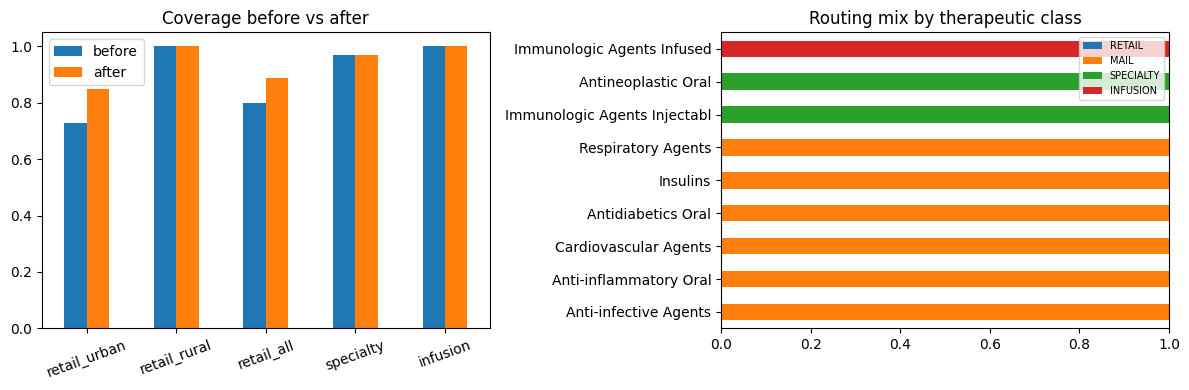

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
cb[['before','after']].plot.bar(ax=ax[0],rot=20); ax[0].set_title('Coverage before vs after'); ax[0].set_ylim(0,1.05)
mx.plot.barh(stacked=True, ax=ax[1]); ax[1].set_title('Routing mix by therapeutic class'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Scenario suite, reference script format

In [11]:
def build_scenarios(base, natural, ceil):
    # Floors are calibrated to THIS data: interpolated between the coverage the cheapest network
    # delivers on its own (natural) and the most any network can deliver (ceiling). A floor below
    # natural is inert; a floor above ceiling is infeasible. Scenarios walk that band.
    def lvl(lens, f):  # f = fraction of the natural->ceiling gap to demand
        return round(natural[lens] + f*(ceil[lens]-natural[lens]) - 1e-4, 4)
    F = lambda fu, fr: {'URBAN':(4.0, lvl('retail_urban',fu)), 'RURAL':(15.0, lvl('retail_rural',fr))}
    S = lambda f: lvl('specialty', f)
    return [
      dict(name='Lowest Cost',        budget=None,           LAMBDA_D=0.2, CONTRACT_WEIGHT=1.0, DISTANCE_PENALTY=0.2,
           CURRENT_NETWORK_REWARD=0.0, FLOORS=F(-0.5,-0.5), SPEC_FLOOR=S(-0.5)),
      dict(name='Mid Cost',           budget=int(base*1.15), LAMBDA_D=1.0, CONTRACT_WEIGHT=2.0, DISTANCE_PENALTY=0.5,
           EXTRA_CHOICE_REWARD=1.0, CURRENT_NETWORK_REWARD=0.5, FLOORS=F(0.30,0.30), SPEC_FLOOR=S(0.30)),
      dict(name='Better Coverage',    budget=int(base*1.35), LAMBDA_D=2.0, CONTRACT_WEIGHT=2.5, DISTANCE_PENALTY=1.0,
           EXTRA_CHOICE_REWARD=3.0, CURRENT_NETWORK_REWARD=1.0, FLOORS=F(0.65,0.65), SPEC_FLOOR=S(0.65)),
      dict(name='Highest Cost',       budget=int(base*1.70), LAMBDA_D=4.0, CONTRACT_WEIGHT=3.0, DISTANCE_PENALTY=1.5,
           EXTRA_CHOICE_REWARD=5.0, CURRENT_NETWORK_REWARD=2.0, FLOORS=F(0.95,0.95), SPEC_FLOOR=S(0.95)),
      dict(name='Biggest Percentage', budget=int(base*1.40), LAMBDA_D=1.0, CONTRACT_WEIGHT=14.0, DISTANCE_PENALTY=0.2,
           CURRENT_NETWORK_REWARD=0.5, FLOORS=F(0.30,0.30), SPEC_FLOOR=S(0.30)),
      dict(name='Specialty Focus',    budget=int(base*1.40), LAMBDA_D=2.0, CONTRACT_WEIGHT=3.0, DISTANCE_PENALTY=0.6,
           CURRENT_NETWORK_REWARD=0.5, FLOORS=F(0.30,0.30), SPEC_FLOOR=S(1.0)),
      dict(name='Member Stability',   budget=int(base*1.60), LAMBDA_D=25.0, CONTRACT_WEIGHT=2.0, DISTANCE_PENALTY=0.5,
           CURRENT_NETWORK_REWARD=4.0, FLOORS=F(0.30,0.30), SPEC_FLOOR=S(0.30)),
      dict(name='Mail Forward',       budget=int(base*1.20), LAMBDA_D=1.0, CONTRACT_WEIGHT=2.0, DISTANCE_PENALTY=4.0,
           CURRENT_NETWORK_REWARD=0.5, FLOORS=F(0.30,0.30), SPEC_FLOOR=S(0.30)),
      dict(name='Urban Maximum',      budget=int(base*1.90), LAMBDA_D=4.0, CONTRACT_WEIGHT=2.5, DISTANCE_PENALTY=1.0,
           EXTRA_CHOICE_REWARD=3.0, CURRENT_NETWORK_REWARD=1.0, FLOORS=F(1.0,0.65), SPEC_FLOOR=S(0.65)),
    ]

def set_budget(m_,b):
    if hasattr(m_,'bc'): m_.del_component(m_.bc)
    if b is not None: m_.bc = Constraint(expr=cost_expr(m_)+admin_expr(m_) <= b)
def run(s):
    P=dict(CONFIG); P.update({k:v for k,v in s.items() if k in ('LAMBDA_D','CONTRACT_WEIGHT','DISTANCE_PENALTY','EXTRA_CHOICE_REWARD','CURRENT_NETWORK_REWARD')})
    P.setdefault('EXTRA_CHOICE_REWARD',0.0)
    set_objective(mdl,P); set_budget(mdl,s.get('budget'))
    if 'FLOORS' in s: set_floors(mdl, s['FLOORS'], s.get('SPEC_FLOOR', CONFIG['SPEC_FLOOR']))
    r_,t_=solve(mdl); Mi=metrics(mdl)
    return dict(scenario=s['name'], status=str(r_.solver.termination_condition), sites=len(Mi['selected']),
                total_cost=round(Mi['total']), savings_pct=round(100*(1-Mi['drug']/B0),1),
                cov_before=round(coverage_before['retail_all'],3), cov_after=round(Mi['cov_after']['retail_all'],3),
                cov_delta=round(Mi['cov_after']['retail_all']-coverage_before['retail_all'],3),
                disruption_pct=round(Mi['disr_pct'],1), kept_pct=round(Mi['kept_pct'],1),
                choice_pct=round(Mi['extra_choice_rate'],1), cov_all=round(Mi['coverage_all_members'],3),
                avg_dist=round(Mi['assigned_avg_dist'],2),
                awp_discount_pct=round(Mi['contract'],1), solve_s=round(t_,1)), Mi
# Base run: floors switched off. Whatever coverage this cheapest lawful network delivers on its
# own is the NATURAL level; scenario floors are then calibrated between natural and the ceiling.
base, base_M = run(dict(name='Base', budget=None, LAMBDA_D=0.2, CONTRACT_WEIGHT=1.0, DISTANCE_PENALTY=0.2,
                        CURRENT_NETWORK_REWARD=0.0, FLOORS={'URBAN':(4.0,0.0),'RURAL':(15.0,0.0)}, SPEC_FLOOR=0.0))
natural = base_M['cov_after']
print(f"base cheapest lawful network: ${base['total_cost']:,}  ({base['sites']} sites)")
print("natural coverage :", {k:round(v,3) for k,v in natural.items()})
print("ceiling          :", {k:round(v,3) for k,v in ceiling.items()})
print("-> scenario floors are placed inside this band so each one genuinely binds")
outs,scenario_metrics=[],{}
for s in build_scenarios(base['total_cost'], natural, ceiling):
    o,Mi=run(s); outs.append(o); scenario_metrics[s['name']]=Mi
summary=pd.DataFrame(outs)
print('=== Scenario Summary ==='); print(summary.to_string(index=False))

base cheapest lawful network: $9,933,960  (135 sites)
natural coverage : {'retail_urban': np.float64(0.729), 'retail_rural': np.float64(1.0), 'retail_all': np.float64(0.799), 'specialty': 0.949, 'infusion': 1.0}
ceiling          : {'retail_urban': np.float64(0.889), 'retail_rural': np.float64(1.0), 'retail_all': np.float64(0.918), 'specialty': 0.996, 'infusion': 1.0}
-> scenario floors are placed inside this band so each one genuinely binds


=== Scenario Summary ===
          scenario  status  sites  total_cost  savings_pct  cov_before  cov_after  cov_delta  disruption_pct  kept_pct  choice_pct  cov_all  avg_dist  awp_discount_pct  solve_s
       Lowest Cost optimal    135     9933960          5.2       0.798      0.799      0.001             0.5       1.8         0.0    0.802     14.57              93.4     14.6
          Mid Cost optimal    142    10143960          5.2       0.798      0.837      0.038             0.4       1.8        75.6    0.834     13.71              93.5     14.7
   Better Coverage optimal    151    10413960          5.2       0.798      0.876      0.078             0.3       1.8        79.8    0.874     13.42              93.5     14.5
      Highest Cost optimal    173    11205402          3.1       0.798      0.912      0.113             0.1       1.9        88.1    0.909     13.23              93.6     14.0
Biggest Percentage optimal    143    10364235          2.2       0.798      0.837      0.0

## 10. Disruption impact: the business view

Ported from the reference script's diagnostics and extended. For each scenario: who loses their pharmacy,
how many extra miles they now travel to the nearest selected alternative, the reference script's distance
gap breach counts (allowed gap: mail unlimited, specialty 2 miles, standard 2 urban and 5 rural), and the
savings earned per disrupted member. This is the table that lets the business weigh a million of savings
against the members who pay for it in miles, and decide what to hand back.

In [12]:
rows=[]; detail={}
for name, Mi in scenario_metrics.items():
    sel=set(Mi['selected']); recs=[]
    breach=0; gap_gt2=0
    for m_ in MEMBERS:
        cp_=cur_of.get(m_)
        if not isinstance(cp_,str): continue
        t_=ph.loc[cp_,'PHR_TYPE_CD']
        realized=min([D[(m_,p_)] for p_ in sel if ph.loc[p_,'PHR_TYPE_CD']==t_], default=float('nan'))
        # reference script breach rule: gap vs nearest eligible over ALL candidates
        near_all=min([D[(m_,p_)] for p_ in SITES if ph.loc[p_,'PHR_TYPE_CD']==t_])
        gap_=realized-near_all
        if me.loc[m_,'MAIL_ORDR_CORP_IND']==1: allowed=float('inf')
        elif me.loc[m_,'SPECIALTY_DRUG_PRG_MBR_IND']==1: allowed=2.0
        else: allowed=2.0 if me.loc[m_,'MBR_URBAN_RURAL_CD']=='URBAN' else 5.0
        if gap_>allowed: breach+=1
        if me.loc[m_,'MAIL_ORDR_CORP_IND']==0 and me.loc[m_,'SPECIALTY_DRUG_PRG_MBR_IND']==0 and gap_>2.0: gap_gt2+=1
        if cp_ in sel: continue
        recs.append(dict(MBR_SK=m_, fills=int(me.loc[m_,'TOT_FILLS']),
                         old_miles=round(D[(m_,cp_)],1), new_miles=round(realized,1),
                         extra_miles=round(realized-D[(m_,cp_)],1)))
    dd_=pd.DataFrame(recs); detail[name]=dd_
    saved=B0-Mi['drug']
    rows.append(dict(scenario=name, members_disrupted=len(dd_),
        extra_mi_median=round(dd_.extra_miles.median(),1) if len(dd_) else 0.0,
        extra_mi_max=round(dd_.extra_miles.max(),1) if len(dd_) else 0.0,
        annual_extra_member_miles=int((dd_.extra_miles.clip(lower=0)*dd_.fills*2).sum()) if len(dd_) else 0,
        gap_breaches=breach, std_gap_gt2=gap_gt2,
        drug_savings=int(saved),
        savings_per_disrupted=int(saved/len(dd_)) if len(dd_) else None))
impact=pd.DataFrame(rows)
print('=== Disruption Impact (reference script diagnostics, extended) ===')
print(impact.to_string(index=False))
worst=[n for n in detail if len(detail[n])>0]
if worst:
    n0=max(worst, key=lambda n: len(detail[n]))
    print(chr(10)+f"Worst affected members, {n0}:")
    print(detail[n0].sort_values('extra_miles',ascending=False).head(8).to_string(index=False))

=== Disruption Impact (reference script diagnostics, extended) ===
          scenario  members_disrupted  extra_mi_median  extra_mi_max  annual_extra_member_miles  gap_breaches  std_gap_gt2  drug_savings  savings_per_disrupted
       Lowest Cost                575             -1.3          11.5                       6959           223          175        325988                    566
          Mid Cost                483             -1.5          11.5                       3810           157          130        325988                    674
   Better Coverage                335             -1.9          11.5                       1917           102           63        325988                    973
      Highest Cost                128             -2.0          11.5                        761            48           15        194546                   1519
Biggest Percentage                485             -1.6          11.2                       3640           154          130        135

## 11. Reference script parity outputs

Per member results table and CSV exports in the reference script's format, plus its uncoverable style
warning adapted to our routing: members whose only retail option is the nearest site fallback, meaning
nothing lies inside their access radius.

In [13]:
import os
os.makedirs('exports', exist_ok=True)
# reference script's three CSVs, from our tables
members_dim.to_csv('exports/synthetic_members.csv', index=False)
pharm_dim.to_csv('exports/synthetic_pharmacies.csv', index=False)
pd.DataFrame([dict(MBR_SK=m, PHR_PMT_CNTR_SK=p, distance_miles=D[(m,p)]) for m in MEMBERS for p in SITES])   .to_csv('exports/synthetic_distances.csv', index=False)
claims.to_csv('exports/synthetic_claims.csv', index=False)

# per member results, reference format, for the default solve
sel0=set(M['selected'])
mr=[]
for m in MEMBERS:
    cp=cur_of.get(m); is_std=m in set(STD)
    mr.append(dict(MBR_SK=m,
        covered=int(any(p in sel0 for p in N_ret[m])) if is_std else None,
        kept_current=int(isinstance(cp,str) and cp in sel0),
        has_extra_choice=int(len([p for p in N_nearby[m] if p in sel0])>=2) if is_std else None,
        current_pharmacy=cp))
member_results_df=pd.DataFrame(mr)
member_results_df.to_csv('exports/member_results.csv', index=False)
no_radius=[m for m in STD if not N_ret[m]]
print(f"exports written: 4 synthetic tables + member_results.csv ({len(member_results_df)} rows)")
if no_radius:
    print(f"WARNING: {len(no_radius)} standard members have NO retail option inside their access radius;")
    print("their routing uses the nearest-site fallback (reference script marks these uncoverable).")

exports written: 4 synthetic tables + member_results.csv (1500 rows)
their routing uses the nearest-site fallback (reference script marks these uncoverable).


## 12. Interactive review charts

Built for the business conversation. Hover any point for the full record of that design. Each chart answers
one question a decision maker will ask.

In [14]:
import plotly.express as px
import plotly.graph_objects as go
biz = summary.merge(impact, on='scenario')
biz['total_cost_m'] = biz.total_cost/1e6
biz['access_pct'] = 100*biz.cov_after
hov = {'scenario':True,'total_cost_m':':.2f','savings_pct':True,'access_pct':':.1f',
       'disruption_pct':True,'members_disrupted':True,'extra_mi_median':True,
       'savings_per_disrupted':True,'choice_pct':True,'sites':True}

# Question one: what does each additional dollar buy in access
f1 = px.line(biz.sort_values('total_cost_m'), x='total_cost_m', y='access_pct', text='scenario',
             markers=True, hover_data=hov,
             title='What each budget buys. Network cost against members with good access')
f1.add_hline(y=100*coverage_before['retail_all'], line_dash='dot',
             annotation_text='today', annotation_position='bottom right')
f1.update_traces(textposition='top center', line_color='#1F3B57', marker_size=11)
f1.update_layout(xaxis_title='Total network cost, millions', yaxis_title='Members with good access, percent',
                 template='plotly_white', height=430)
f1.show()

# Question two: savings against the members who carry the change
f2 = px.scatter(biz, x='members_disrupted', y='drug_savings', size='savings_per_disrupted',
                color='scenario', hover_data=hov, size_max=44,
                title='Savings against the members asked to move. Bubble size is savings per affected member')
f2.update_layout(xaxis_title='Members whose pharmacy leaves the network',
                 yaxis_title='Annual drug savings, dollars', template='plotly_white', height=430)
f2.show()

# Question three: the member experience ledger per scenario
f3 = go.Figure()
f3.add_bar(name='Access percent', x=biz.scenario, y=biz.access_pct, marker_color='#1F3B57')
f3.add_bar(name='Members with real choice, percent', x=biz.scenario, y=biz.choice_pct, marker_color='#5C8CB8')
f3.add_bar(name='Disruption percent of visits', x=biz.scenario, y=biz.disruption_pct, marker_color='#B3202C')
f3.update_layout(barmode='group', title='The member experience each scenario delivers',
                 template='plotly_white', height=430, yaxis_title='Percent')
f3.show()

# Question four: where does the money sit against the miles members drive
f4 = px.scatter(biz, x='annual_extra_member_miles', y='savings_pct', color='scenario', text='scenario',
                hover_data=hov, title='Savings rate against total extra member miles per year')
f4.update_traces(textposition='top center', marker_size=13)
f4.update_layout(xaxis_title='Annual extra member miles, sum across disrupted members',
                 yaxis_title='Drug savings, percent of baseline', template='plotly_white', height=430)
f4.show()
print('interactive charts rendered')

interactive charts rendered


## 13. Glossary and decisions requested

**Access.** Share of members with an in network pharmacy of the right kind within their travel distance.
Measured separately for retail, specialty and infusion populations, weighted by fill volume.

**Disruption.** Share of fill volume belonging to members whose current pharmacy leaves the network. Priced
in the objective and scaled by how far the next alternative sits.

**Choice.** Share of standard members with at least two in network retail options inside their nearby ring.

**Savings per disrupted member.** Annual drug savings divided by the count of members asked to move. The
number that sizes a make whole offer such as a plan credit.

**Decisions requested from the business.**
1. Confirm the per pharmacy administration cost currently assumed at thirty thousand dollars a year.
2. Confirm which chains contract all or nothing.
3. Confirm whether contract access standards are written in straight line miles or drive time.
4. Choose the scenario philosophy to carry into client conversations.
5. Approve the data request in Section 1 so the model moves from synthetic to real.

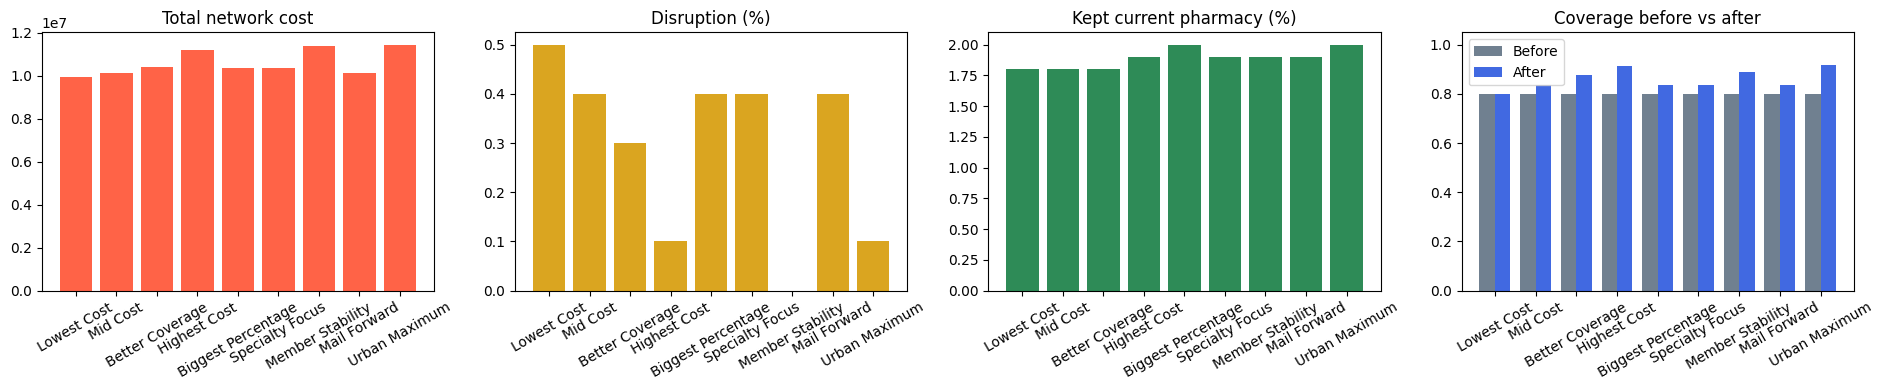

In [15]:
fig,axes=plt.subplots(1,4,figsize=(19,4))
axes[0].bar(summary.scenario,summary.total_cost,color='tomato'); axes[0].set_title('Total network cost')
axes[1].bar(summary.scenario,summary.disruption_pct,color='goldenrod'); axes[1].set_title('Disruption (%)')
axes[2].bar(summary.scenario,summary.kept_pct,color='seagreen'); axes[2].set_title('Kept current pharmacy (%)')
xp=np.arange(len(summary)); w=0.38
axes[3].bar(xp-w/2,summary.cov_before,w,color='slategray',label='Before')
axes[3].bar(xp+w/2,summary.cov_after,w,color='royalblue',label='After')
axes[3].set_xticks(xp); axes[3].set_xticklabels(summary.scenario); axes[3].set_ylim(0,1.05)
axes[3].set_title('Coverage before vs after'); axes[3].legend()
for a in axes: a.tick_params(axis='x',rotation=30)
plt.tight_layout(); plt.show()

## 10. Solver benchmark

The same model object submitted to several classical solvers. All are exact, so a correct solver must return
the same objective value; what differs is speed. This is the classical half of the benchmark the D-Wave
engagement is built on: when the hybrid CQM results arrive they are judged against this table.

In [16]:
from pyomo.opt import SolverFactory as SF
CANDIDATES = ['appsi_highs','cbc','glpk','scip','gurobi','cplex']
available = []
for s in CANDIDATES:
    try:
        if SF(s).available(exception_flag=False): available.append(s)
    except Exception: pass
print('available solvers:', available)

set_objective(mdl, CONFIG); set_budget(mdl, None); set_floors(mdl, CONFIG['RETAIL_ACCESS'], CONFIG['SPEC_FLOOR'])
bench=[]
for s in available:
    try:
        opt = SF(s); t0=time.time()
        r = opt.solve(mdl, load_solutions=True) if s!='appsi_highs' else opt.solve(mdl)
        dt = time.time()-t0
        obj = value(mdl.obj); sites = sum(round(value(mdl.x[p])) for p in SITES)
        bench.append(dict(solver=s, status=str(r.solver.termination_condition), seconds=round(dt,2),
                          objective=round(obj), sites_selected=sites))
    except Exception as e:
        bench.append(dict(solver=s, status=f'failed: {type(e).__name__}', seconds=None, objective=None, sites_selected=None))
benchmark = pd.DataFrame(bench)
if benchmark.objective.notna().any():
    ref = benchmark.objective.dropna().iloc[0]
    benchmark['obj_gap_pct'] = ((benchmark.objective-ref)/ref*100).round(4)
    fastest = benchmark.seconds.min()
    benchmark['vs_fastest'] = (benchmark.seconds/fastest).round(2)
print(benchmark.to_string(index=False))
print('\nAll exact solvers should agree on the objective. Differences are speed only.')
print('Not available here, add when licensed: Gurobi, CPLEX, SCIP. The model needs no change for any of them.')

available solvers: ['appsi_highs', 'cbc', 'glpk']


     solver  status  seconds  objective  sites_selected  obj_gap_pct  vs_fastest
appsi_highs optimal    12.55   12789302             180          0.0        2.64
        cbc optimal    10.89   12789302             180          0.0        2.29
       glpk optimal     4.75   12789302             180          0.0        1.00

All exact solvers should agree on the objective. Differences are speed only.
Not available here, add when licensed: Gurobi, CPLEX, SCIP. The model needs no change for any of them.


## 11. Visualisations

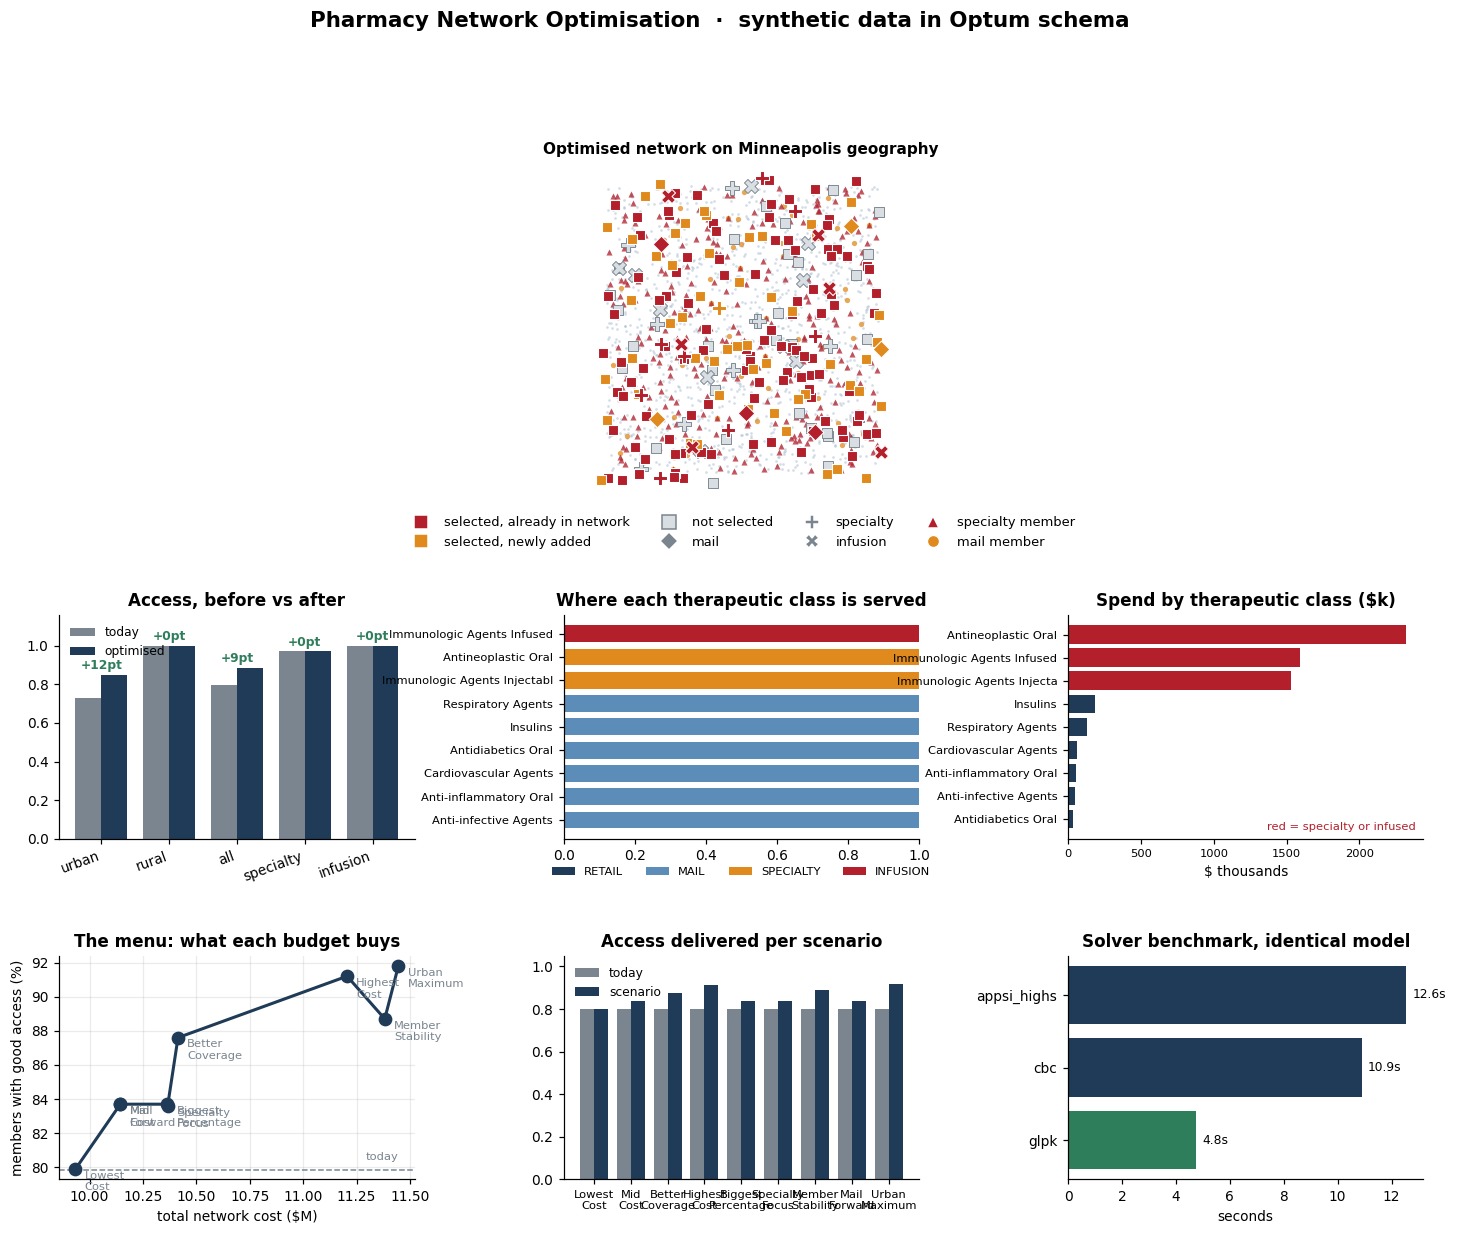

In [17]:
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,
                     'font.size':9,'axes.titlesize':11,'axes.titleweight':'bold'})
NAVY, RED, ORANGE, GREY, LGREY, GREEN = '#1F3B57','#B3202C','#E08A1E','#7A8590','#D9DEE3','#2E7D5B'

def draw_network(ax, Mi, title):
    sel=set(Mi['selected'])
    std=me.loc[[m for m in STD]]; sp=me.loc[SPECM]; ml=me.loc[[m for m in MEMBERS if m not in STD]]
    ax.scatter(std.MBR_LON, std.MBR_LAT, s=3, c='#9FB3C8', alpha=.45, linewidths=0)
    ax.scatter(ml.MBR_LON, ml.MBR_LAT, s=12, c=ORANGE, alpha=.75, linewidths=0)
    ax.scatter(sp.MBR_LON, sp.MBR_LAT, s=16, c=RED, marker='^', alpha=.75, linewidths=0)
    for typ, mk, sz in [('RETAIL','s',42),('MAIL','D',60),('SPECIALTY','P',85),('INFUSION','X',85)]:
        sub=ph[ph.PHR_TYPE_CD==typ]
        out=sub[~sub.index.isin(sel)]; inn=sub[sub.index.isin(sel)]
        ax.scatter(out.PHR_LON,out.PHR_LAT,s=sz,c=LGREY,marker=mk,edgecolors=GREY,linewidths=.6,zorder=3)
        cur=inn[inn.PHR_IN_CURRENT_NTWK==1]; new=inn[inn.PHR_IN_CURRENT_NTWK==0]
        ax.scatter(cur.PHR_LON,cur.PHR_LAT,s=sz,c=RED,marker=mk,edgecolors='white',linewidths=.7,zorder=4)
        ax.scatter(new.PHR_LON,new.PHR_LAT,s=sz,c=ORANGE,marker=mk,edgecolors='white',linewidths=.7,zorder=4)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect(1/np.cos(np.radians(44.98)))     # true geographic aspect at this latitude
    for s_ in ax.spines.values(): s_.set_visible(False)

fig = plt.figure(figsize=(16,12))
gs = fig.add_gridspec(3,3, height_ratios=[1.5,1,1], hspace=.45, wspace=.42)

ax = fig.add_subplot(gs[0,:]); draw_network(ax, M, 'Optimised network on Minneapolis geography')
leg=[Line2D([0],[0],marker='s',color='w',markerfacecolor=RED,markersize=9,label='selected, already in network'),
     Line2D([0],[0],marker='s',color='w',markerfacecolor=ORANGE,markersize=9,label='selected, newly added'),
     Line2D([0],[0],marker='s',color='w',markerfacecolor=LGREY,markeredgecolor=GREY,markersize=9,label='not selected'),
     Line2D([0],[0],marker='D',color='w',markerfacecolor=GREY,markersize=8,label='mail'),
     Line2D([0],[0],marker='P',color='w',markerfacecolor=GREY,markersize=9,label='specialty'),
     Line2D([0],[0],marker='X',color='w',markerfacecolor=GREY,markersize=9,label='infusion'),
     Line2D([0],[0],marker='^',color='w',markerfacecolor=RED,markersize=8,label='specialty member'),
     Line2D([0],[0],marker='o',color='w',markerfacecolor=ORANGE,markersize=8,label='mail member')]
ax.legend(handles=leg, loc='upper center', bbox_to_anchor=(.5,-.02), ncol=4, frameon=False, fontsize=8.5)

ax = fig.add_subplot(gs[1,0])
lbl=[k.replace('retail_','').replace('_',' ') for k in cb.index]
xp=np.arange(len(cb)); w=.38
ax.bar(xp-w/2, cb.before, w, color=GREY, label='today')
ax.bar(xp+w/2, cb.after,  w, color=NAVY, label='optimised')
for i,(b_,a_) in enumerate(zip(cb.before,cb.after)):
    ax.annotate(f'+{100*(a_-b_):.0f}pt',(i,max(a_,b_)+.03),ha='center',fontsize=8,color=GREEN,fontweight='bold')
ax.set_xticks(xp); ax.set_xticklabels(lbl, rotation=20, ha='right'); ax.set_ylim(0,1.16)
ax.set_title('Access, before vs after'); ax.legend(frameon=False, fontsize=8)

ax = fig.add_subplot(gs[1,1])
order=[c for c in ['RETAIL','MAIL','SPECIALTY','INFUSION'] if c in mx.columns]
cmap={'RETAIL':NAVY,'MAIL':'#5C8CB8','SPECIALTY':ORANGE,'INFUSION':RED}
left=np.zeros(len(mx))
for c in order:
    ax.barh(range(len(mx)), mx[c].values, left=left, color=cmap[c], height=.72, label=c)
    left = left + mx[c].values
ax.set_yticks(range(len(mx))); ax.set_yticklabels(mx.index, fontsize=7.5)
ax.set_xlim(0,1); ax.set_title('Where each therapeutic class is served')
ax.legend(fontsize=7.5, frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(.5,-.08))

ax = fig.add_subplot(gs[1,2])
spend = pd.Series({dd.loc[k,'GPI_CLASS_NM'][:26]: sum(C_cost[t]*value(mdl.y[t]) for t in YIDX if t[1]==k) for k in KL}).sort_values()
cols=[RED if dd.set_index('GPI_CLASS_NM').loc[[i for i in dd.GPI_CLASS_NM if i[:26]==n][0],'SPECIALTY_DRUG_PRG_IND']==1 else NAVY for n in spend.index]
ax.barh(spend.index, spend.values/1000, color=cols); ax.set_title('Spend by therapeutic class ($k)')
ax.tick_params(labelsize=7.5); ax.set_xlabel('$ thousands')
ax.annotate('red = specialty or infused', xy=(.98,.04), xycoords='axes fraction', ha='right', fontsize=7.5, color=RED)

ax = fig.add_subplot(gs[2,0])
s_=summary.sort_values('total_cost')
ax.plot(s_.total_cost/1e6, s_.cov_after*100, '-o', color=NAVY, lw=2, ms=8, zorder=3)
for _,r_ in s_.iterrows():
    ax.annotate(r_.scenario.replace(' ', chr(10)),(r_.total_cost/1e6, r_.cov_after*100),
                textcoords='offset points', xytext=(6,-14), fontsize=7.5, color=GREY)
ax.axhline(coverage_before['retail_all']*100, ls='--', lw=1, color=GREY)
ax.annotate('today', (s_.total_cost.max()/1e6, coverage_before['retail_all']*100+.6), fontsize=7.5, color=GREY, ha='right')
ax.set_xlabel('total network cost ($M)'); ax.set_ylabel('members with good access (%)')
ax.set_title('The menu: what each budget buys'); ax.grid(alpha=.25)

ax = fig.add_subplot(gs[2,1])
xp=np.arange(len(summary)); w=.38
ax.bar(xp-w/2, summary.cov_before, w, color=GREY, label='today')
ax.bar(xp+w/2, summary.cov_after,  w, color=NAVY, label='scenario')
ax.set_xticks(xp); ax.set_xticklabels([s.replace(' ', chr(10)) for s in summary.scenario], fontsize=7.5)
ax.set_ylim(0,1.05); ax.set_title('Access delivered per scenario'); ax.legend(frameon=False, fontsize=8)

ax = fig.add_subplot(gs[2,2])
if 'seconds' in benchmark and benchmark.seconds.notna().any():
    bb=benchmark.dropna(subset=['seconds']).sort_values('seconds')
    bars=ax.barh(bb.solver, bb.seconds, color=[GREEN if i==0 else NAVY for i in range(len(bb))])
    for b_,v_ in zip(bars,bb.seconds): ax.annotate(f'{v_:.1f}s',(v_,b_.get_y()+b_.get_height()/2),
                                                   va='center',xytext=(4,0),textcoords='offset points',fontsize=8)
    ax.set_title('Solver benchmark, identical model'); ax.set_xlabel('seconds')
plt.suptitle('Pharmacy Network Optimisation  ·  synthetic data in Optum schema', fontsize=14, fontweight='bold', y=.995)
plt.show()

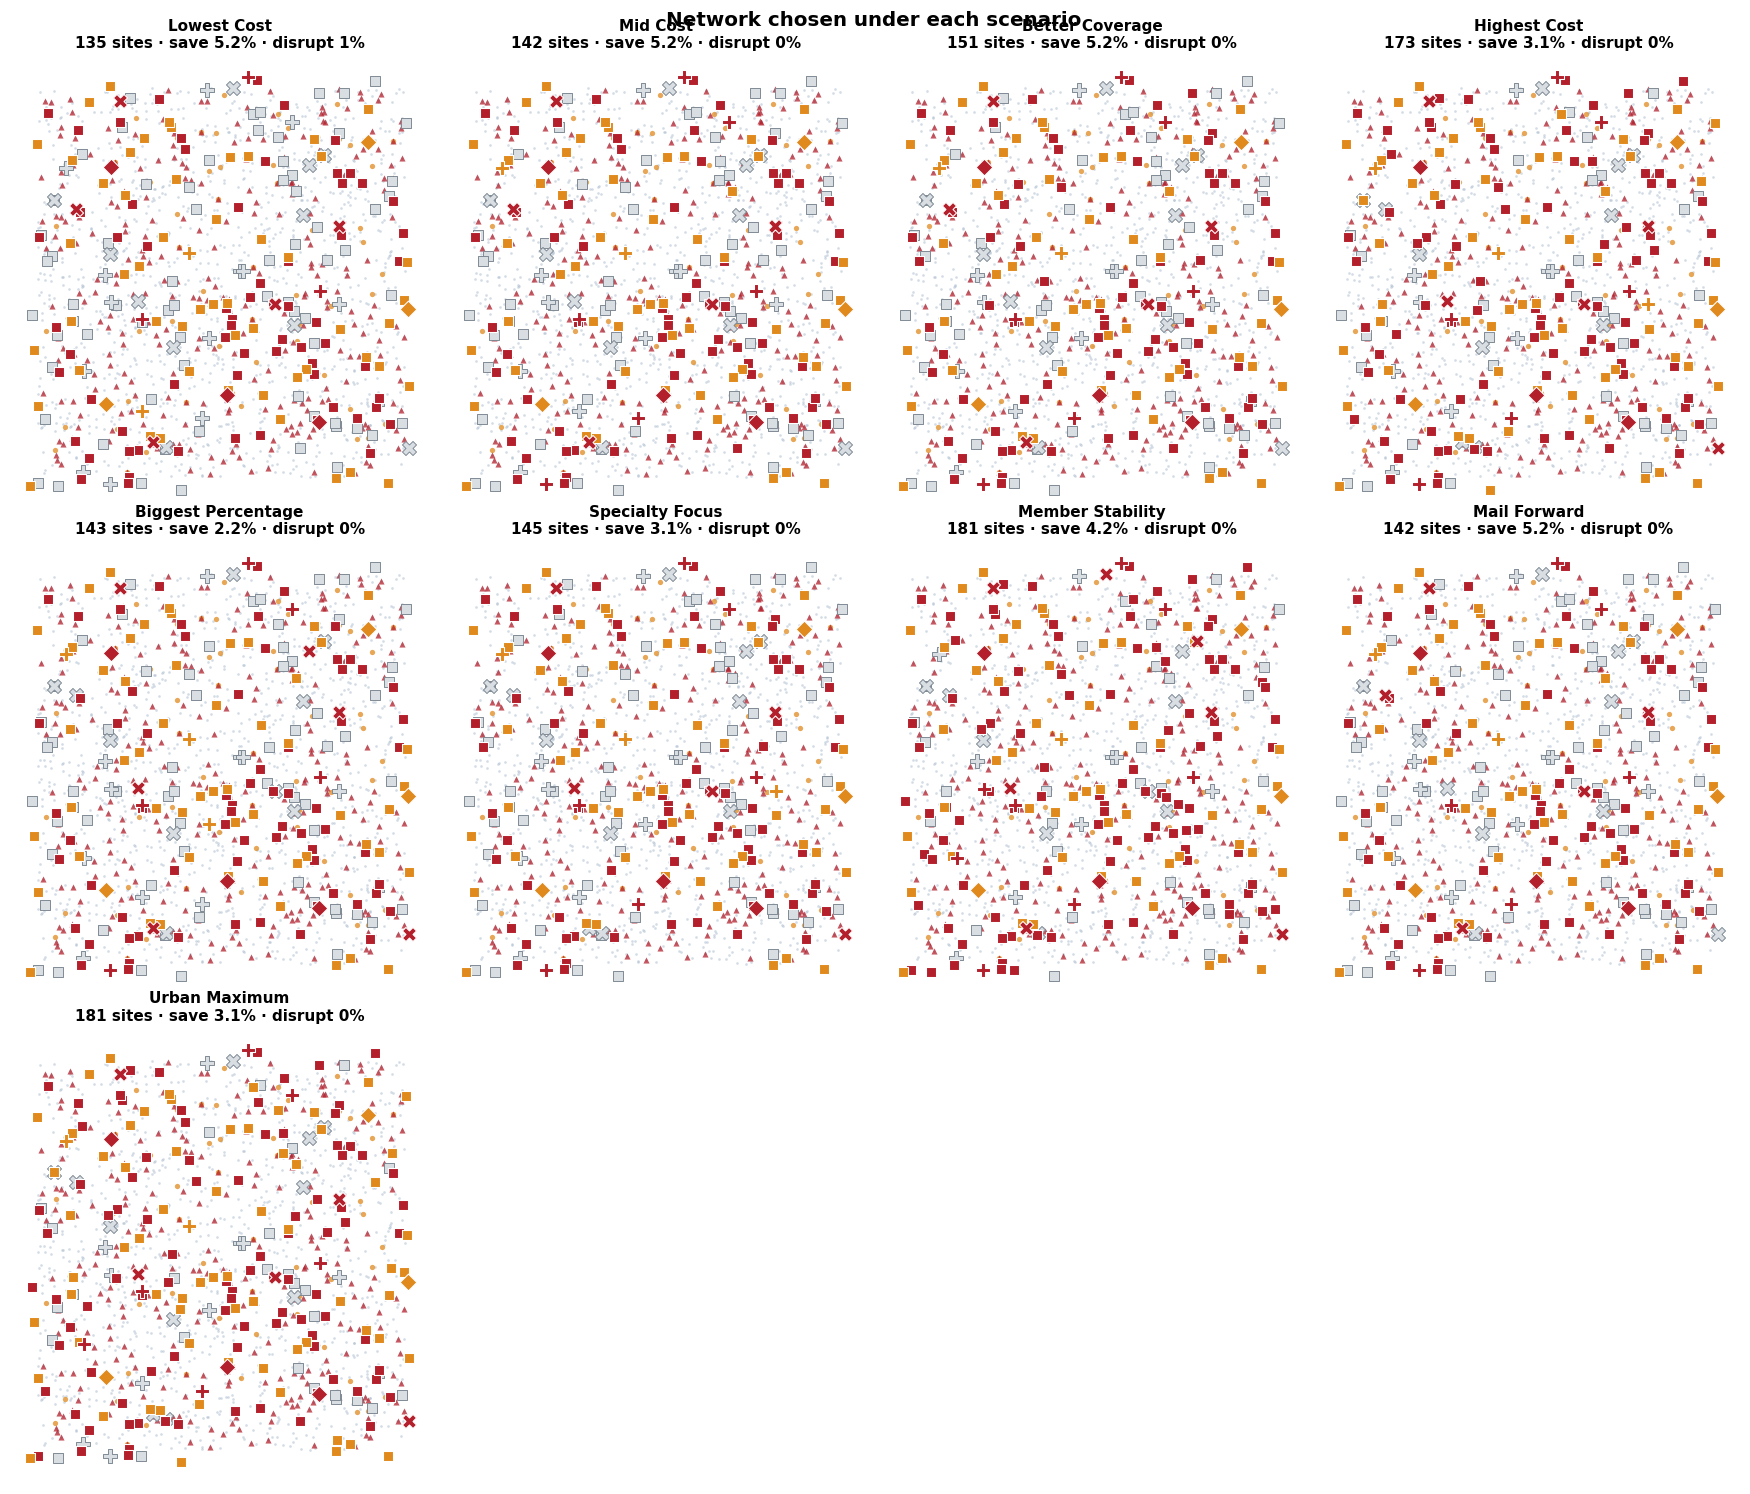

In [18]:
nsc=len(scenario_metrics); ncol=4; nrow=int(np.ceil(nsc/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.0*ncol, 4.6*nrow))
axes=np.atleast_1d(axes).ravel()
for a_ in axes[nsc:]: a_.axis('off')
for ax,(nm,Mi) in zip(axes, scenario_metrics.items()):
    draw_network(ax, Mi, f"{nm}\n{len(Mi['selected'])} sites · save {100*(1-Mi['drug']/B0):.1f}% · disrupt {Mi['disr_pct']:.0f}%")
plt.suptitle('Network chosen under each scenario', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()